In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Path to dataset files:", path)

c:\Users\Zain Sheikh\.conda\envs\python_ml\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Zain Sheikh\.cache\kagglehub\datasets\uciml\sms-spam-collection-dataset\versions\1


<!-- Cleaning -->

# Cleaning data

In [3]:
import os


# 1. Folder ke andar mojood files ko check karein
print("Folder ki files:", os.listdir(path))

# 2. File ka mukammal rasta banayen (Hum farz kar rahe hain file ka naam 'spam.csv' hai)
# Agar pichli line mein naam kuch aur aaye, to yahan change kar lijiyega
file_path = os.path.join(path, 'spam.csv')

# 3. Data ko DataFrame mein load karein 
df = pd.read_csv(file_path, encoding='latin-1')

# 4. dro insignificant columns and change columns ke name 
df = df[['v1', 'v2']]
df.columns = ['Label', 'Message']

# 5. Watch data on Screen
print("\nData Load Ho Gaya! Pehli 5 rows:")
print(df.head())

Folder ki files: ['spam.csv']

Data Load Ho Gaya! Pehli 5 rows:
  Label                                            Message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
df.sample(5)

,Label,Message
897,ham,I'm used to it. I just hope my agents don't dr...
2569,ham,Ultimately tor motive tui achieve korli.
2583,ham,"Goodmorning, today i am late for 1hr."
981,ham,Reckon need to be in town by eightish to walk ...
26,ham,Lol your always so convincing.


In [5]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [6]:
df['Label'] = encoder.fit_transform(df['Label'])
df.head()

,Label,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
# Missing values check karein
df.isnull().sum()

Label      0
Message    0
dtype: int64

In [8]:
#  check fo duplicate values
df.duplicated().sum()

np.int64(403)

In [9]:
# remove duplitcate values
df = df.drop_duplicates(keep='first')

#  2.EDA

In [10]:
df['Label'].value_counts()

Label
0    4516
1     653
Name: count, dtype: int64

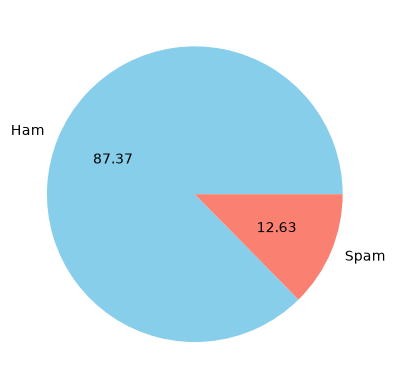

In [11]:
import matplotlib.pyplot as plt
plt.pie(df['Label'].value_counts(), labels=['Ham', 'Spam'], autopct='%0.2f', colors=['skyblue', 'salmon'])
plt.show()

In [12]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to C:\Users\Zain
[nltk_data]     Sheikh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Zain
[nltk_data]     Sheikh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Zain
[nltk_data]     Sheikh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [13]:
df['num_charecters'] = df['Message'].apply(len)

In [14]:
# number of words
df['num_words'] = df['Message'].apply(lambda x: len(nltk.word_tokenize(x)))

In [15]:
df.head()

,Label,Message,num_charecters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [16]:
df['num_sentences'] = df['Message'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [17]:
df[['num_charecters', 'num_words', 'num_sentences']].describe()

,num_charecters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.460437,1.965564
std,58.236293,13.334441,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [18]:
# ham messages k lye statistics
df[df['Label'] == 0][['num_charecters', 'num_words', 'num_sentences']].describe()

,num_charecters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [19]:
# spam messages k lye statistics
df[df['Label'] == 1][['num_charecters', 'num_words', 'num_sentences']].describe()

,num_charecters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_charecters', ylabel='Count'>

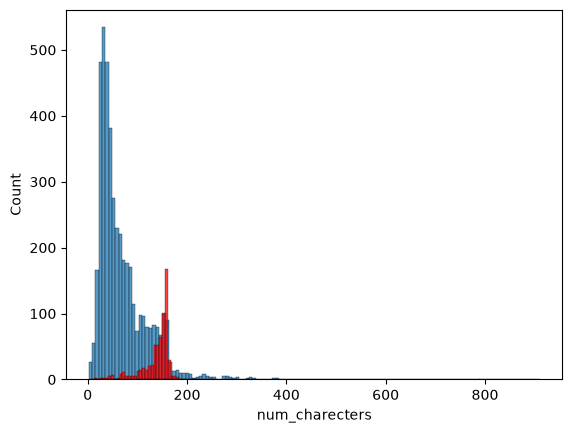

In [20]:
import seaborn as sns
sns.histplot(df[df['Label'] == 0]['num_charecters'])
sns.histplot(df[df['Label'] == 1]['num_charecters'], color='red')

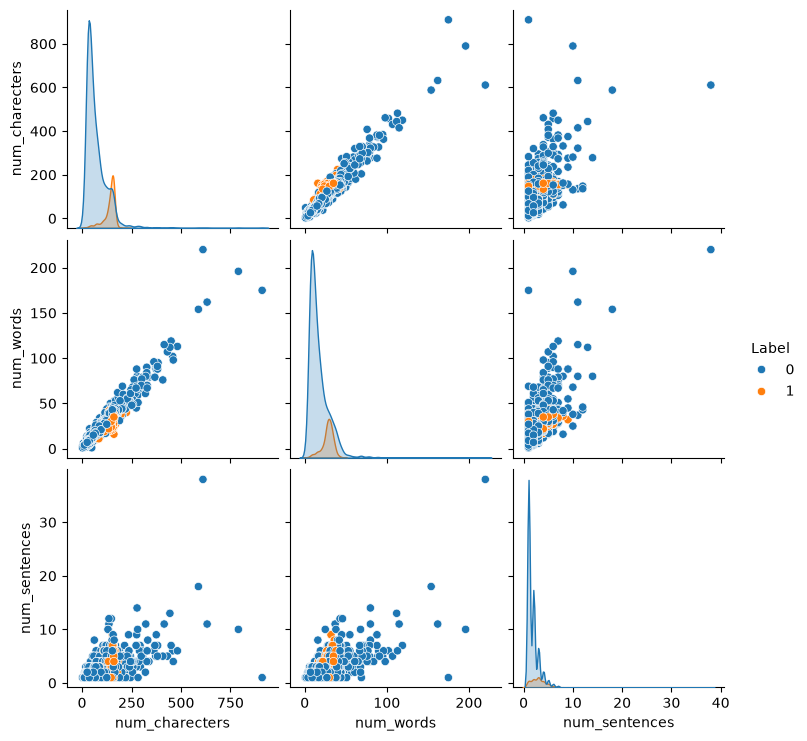

In [21]:
sns.pairplot(df, hue= 'Label')

<Axes: >

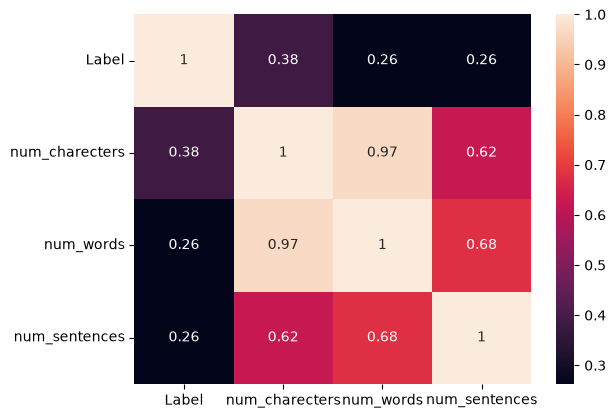

In [53]:
sns.heatmap(df[['Label','num_charecters', 'num_words', 'num_sentences']].corr(), annot=True)

# 3.Data Preprocessing
- Lower case
- Tokenization
- Removing Special Characters
- Removing stop words and punctuation
- Stemming


In [23]:
# string module import
import string
string.punctuation
# nltk.download('stopwords') , you have to run it, if you are running it fo thr first time
from nltk.corpus import stopwords
stopwords.words('english')

# Porter Stemmer import for stemming
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        # check if the word is alphanumeric
        if i.isalnum():
            y.append(i)
    
    text = y[:]
    y.clear()
    
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    
    text = y[:]
    y.clear()
    
    for i in text:
        y.append(ps.stem(i))    
         
    return " ".join(y)

In [24]:
transform_text('Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat')

'go jurong point crazi avail bugi n great world la e buffet cine got amor wat'

In [25]:
# Use Of Port Stemmer
# from nltk.stem.porter import PorterStemmer
# ps = PorterStemmer()
# ps.stem('loved')

In [26]:
df['transformed_text'] = df['Message'].apply(transform_text)

In [31]:
from wordcloud import WordCloud
wc = WordCloud(width=500, height=500, min_font_size=10, background_color='white')

In [32]:
spam_wc = wc.generate(df[df['Label'] == 1]['transformed_text'].str.cat(sep=" "))

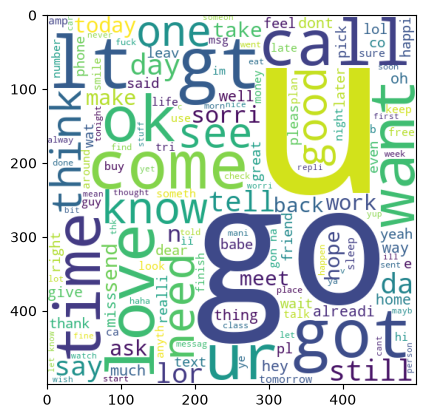

In [51]:
plt.imshow(spam_wc)

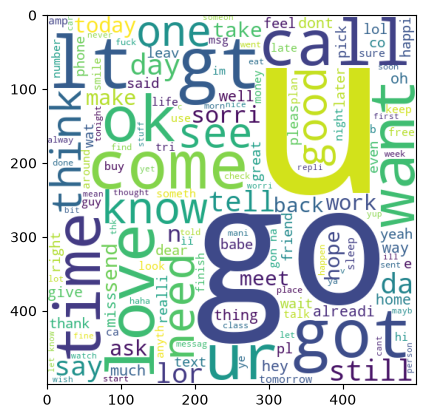

In [34]:
ham_wc = wc.generate(df[df['Label'] == 0]['transformed_text'].str.cat(sep=" "))
plt.imshow(ham_wc)

In [35]:
spam_corpus = []
for msg in df[df['Label'] == 1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [36]:
len(spam_corpus)

9942

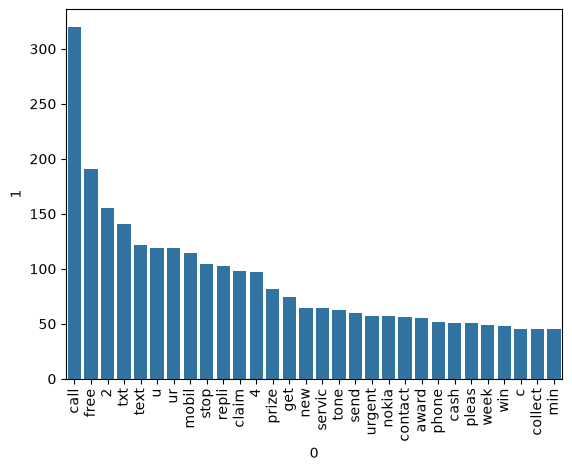

In [37]:
from collections import Counter
sns.barplot(x= pd.DataFrame(Counter(spam_corpus).most_common(30))[0], y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [38]:
ham_corpus = []
for msg in df[df['Label'] == 0]['transformed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

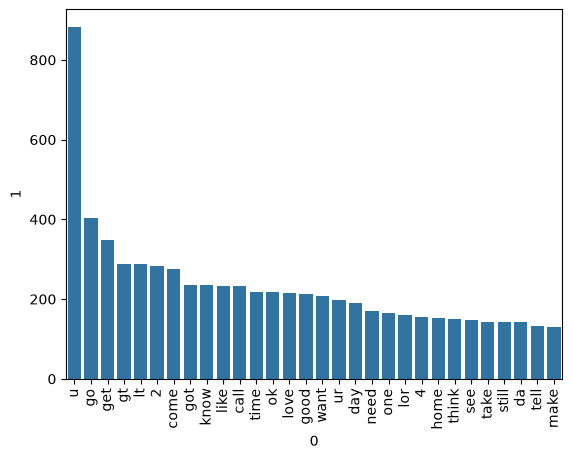

In [39]:
from collections import Counter
sns.barplot(x= pd.DataFrame(Counter(ham_corpus).most_common(30))[0], y=pd.DataFrame(Counter(ham_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

# 4. Model Building

In [40]:
from sklearn.feature_extraction.text import CountVectorizer ,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)


In [41]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [42]:
# from sklearn.preprocessing import MinMaxScaler
# scaler = MinMaxScaler()
# X =scaler.fit_transform(X)

In [43]:
# X = np.hstack((X, df['num_characters'].values.reshape(-1,1)))

In [44]:
y = df['Label'].values

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [46]:
from sklearn.naive_bayes import GaussianNB , MultinomialNB , BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report , precision_score
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [47]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8733075435203095
[[790 106]
 [ 25 113]]
0.5159817351598174


In [48]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9709864603481625
[[896   0]
 [ 30 108]]
1.0


In [49]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9835589941972921
[[895   1]
 [ 16 122]]
0.991869918699187


In [50]:
import pickle
pickle.dump(tfidf, open('vectorizer.pkl', 'wb'))
pickle.dump(mnb, open('model.pkl', 'wb'))

In [54]:
test = transform_text("congratulations you won $1000 dollars click here to")
print("Transformed:", test)
print("Prediction:", mnb.predict(tfidf.transform([test])))

Transformed: congratul 1000 dollar click
Prediction: [0]
